# **MODELO DE CLASIFICACIÓN 2:**
# **Bosque Aleatorio (** Random Forest **)**

Este es un modelo de "ensamble", que se puede entender como **el siguiente paso después de Árbol de Decisión**. En lugar de crear un solo árbol (que puede ser propenso a "memorizar" los datos, u overfitting), un **Random Forest** crea cientos de árboles (`n_estimators=100`) y les pide que "voten" por la mejor clasificación.

**Es como pedir la opinión de 100 expertos en lugar de uno solo.** Son más potentes y robustos que un solo árbol. ¡Ventaja! Al igual que los árboles de decisión, los Random Forest no requieren que escalemos los datos.



****
## **Paso 0: Introducción y Librerías**

**Objetivo:** Entrenar un modelo que pueda predecir la especie de un pingüino basándose en sus medidas físicas (largo y profundidad del pico, largo de la aleta y masa corporal). Usaremos un **Árbol de Decisión**, un modelo fácil de interpretar.

In [48]:
# Librerías para cargar el dataset y construir gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
# Librerías necesarias para el modelo DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [50]:
# Métricas de rendimiento
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

****
## **Paso 1: Cargar los datos**

In [51]:
df = pd.read_csv('df_cleaned.csv')
df.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


***
## **Paso 2: Cargar y Explorar los Datos**
## **Paso 3: Preparación de Datos (Limpieza de datos)**

Vamos a omitir estos pasos, ya que se realizaron durante la limpieza

***
## **Paso 4: Definir Features (X) y Target (y)**

Ahora, separamos nuestros datos en dos partes:

* **Features (`X`):** Las variables de entrada, las "preguntas" que le damos al modelo. Usaremos solo las medidas numéricas.

* **Target (`y`):** La variable de salida, la "respuesta" que queremos predecir (En este caso, las columna `species`).

In [52]:
df.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


* Definimos la columna (o lista de columnas) que será nuestro target `y`

In [53]:
y = df['cut']     # y es una Serie (con un corchete)
y.head()

,cut
0,Ideal
1,Premium
2,Good
3,Premium
4,Good


* Lista de columnas que usaremos como features y definimos `X`

In [54]:
X = df[df.columns.drop('cut')] # X debe ser un DataFrame (con doble corchete)
X.head()

,carat,depth,table,price,x,y,z,Color_D,Color_E,Color_F,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,False,True,False,...,False,False,False,False,False,True,False,False,False,False
1,0.21,59.8,61.0,326,3.89,3.84,2.31,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,0.23,56.9,65.0,327,4.05,4.07,2.31,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,0.29,62.4,58.0,334,4.20,4.23,2.63,False,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,63.3,58.0,335,4.34,4.35,2.75,False,False,False,...,False,True,False,False,False,True,False,False,False,False


In [55]:
# Mostramos las "clases" o especies únicas que el modelo debe aprender
print(f"Clases a predecir: {y.unique()}")

Clases a predecir: ['Ideal' 'Premium' 'Good' 'Very Good' 'Fair']


***
## **Paso 5: Dividir los datos en Train y Test**

Este es el paso más importante del Machine Learning. El set de datos se divide entre datos para entrenar el modelo y el resto para evaluarlo. Generalmente la relación entre datos de entrenamiento y evaluación es **80-20%** o **70-30%**.

* **Set de Entrenamiento (Train):** Lo usaremos para "entrenar" al modelo (80% de los datos).

*  **Set de Prueba (Test):** Lo guardaremos para "evaluar" al modelo con datos que nunca ha visto (20% de los datos).

* Usamos `random_state=42` para que la división aleatoria sea siempre la misma (reproducible).

In [56]:
# Dividimos los datos (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total de datos de entrenamiento (train): {len(X_train)}")
print(f"Total de datos de prueba (test): {len(X_test)}")

Total de datos de entrenamiento (train): 42988
Total de datos de prueba (test): 10748


***
## **Paso 6: Crear y Entrenar el Modelo**

Inicializamos el modelo **Random Forest**. Crearemos un <font color="red">**bosque de 100 árboles**</font> usando `n_estimators=100`.

* Entrenamos el modelo usando el método `.fit()` solo con los datos de entrenamiento.

In [57]:
# 1. Inicializar el modelo
modelo_rf = RandomForestClassifier(max_depth=5,n_estimators=100, random_state=42)

# 2. Entrenar el modelo
modelo_rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, random_state=42)

## <font color="red">**CUIDADO**</font>

* El modelo ya está entrenado. La siguiente celda la usaremos SOLO para evaluar cuanto demora en entrenarse el modelo. **No es necesaria** para ejecutar el modelo

In [58]:
%%timeit
modelo_rf.fit(X_train, y_train)

1.86 s ± 84.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


****
## **Paso 7: Evaluar el Modelo**

Ahora, usamos los datos de prueba (**X_test**) que el modelo nunca vio.

1. Hacemos predicciones con los datos de prueba usando `.predict()`

In [59]:
y_pred = modelo_rf.predict(X_test)

2. Comparamos esas predicciones (**y_pred**) con las respuestas correctas(**y_test**). Primero calculamos la **precisión** usando `.accuracy_score()`:

In [60]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) del modelo: {accuracy * 100:.1f}%")

Precisión (Accuracy) del modelo: 69.4%


3. Comparamos esas predicciones (**y_pred**) con las respuestas correctas(**y_test**). Ahora calculamos la **matriz de confusión** usando usando `.confusion_matrix()`:

In [61]:
print("--- Matriz de Confusión ---")
print("\n(Las filas son el valor REAL, las columnas la PREDICCIÓN) \n")
labels = modelo_rf.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

# La mostramos como un DataFrame para que sea más fácil de leer
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print(cm_df)

--- Matriz de Confusión ---

(Las filas son el valor REAL, las columnas la PREDICCIÓN) 

           Fair  Good  Ideal  Premium  Very Good
Fair        199    21     22       65          8
Good         18   348     66      300        257
Ideal         3     3   3990      251         16
Premium       0     0    342     2400         28
Very Good     2    84    764     1041        520


***
## **Paso 8: Importancia de las Características (** Feature Importance **)**

* Obtenemos las importancias y creamos una serie de Pandas para verlas fácilmente


In [62]:
importances = modelo_rf.feature_importances_
feature_names = X_train.columns
forest_importances = pd.Series(importances, index=feature_names)

# Ordenamos de mayor a menor importancia
forest_importances_sorted = forest_importances.sort_values(ascending=False)

print("--- Importancia de las Características (Random Forest) ---\n")
print(forest_importances_sorted)

--- Importancia de las Características (Random Forest) ---

table      0.547214
depth      0.292434
x          0.047808
y          0.028916
carat      0.027310
z          0.023411
price      0.014392
Cl_I1      0.003858
Cl_SI1     0.003631
Cl_SI2     0.002771
Cl_IF      0.002486
Cl_VVS1    0.001861
Cl_VVS2    0.001664
Color_G    0.000423
Color_E    0.000380
Cl_VS2     0.000282
Color_D    0.000240
Color_H    0.000232
Cl_VS1     0.000203
Color_F    0.000193
Color_J    0.000169
Color_I    0.000123
dtype: float64


* Creamos un gráfico de barras para visualizar el resultado más facilmente

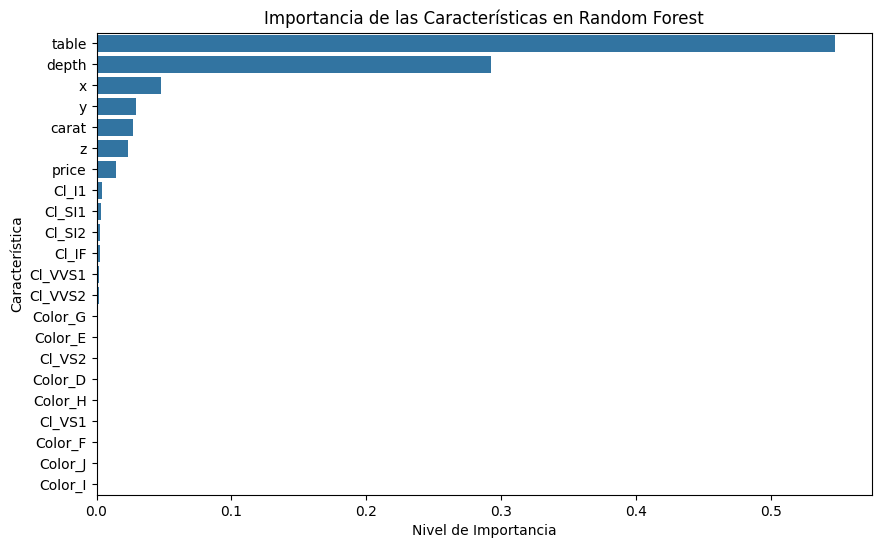

In [63]:
plt.figure(figsize=(10, 6))
sns.barplot(x=forest_importances_sorted.values, y=forest_importances_sorted.index)
plt.title("Importancia de las Características en Random Forest")
plt.xlabel("Nivel de Importancia")
plt.ylabel("Característica")
plt.show()

          feature_names=features_list,       # Nombres de las features
          class_names=labels,                # Nombres de las clases (especies)
          filled=True,                       # Colorear los nodos
          rounded=True,                      # Bordes redondeados